# TASK 1: DATA CLEANING & PREPROCESSING

####  Import Dependencies

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

### Loading and Exploring the data

In [2]:
df = pd.read_csv("Dataset.csv")

In [3]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [4]:
print("Dataset Shape:", df.shape)

print("\nColumn Information:")
df.info()



Dataset Shape: (8790, 10)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [5]:
print(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64
Duplicate Rows: 0


### Clean and Standardize the Data

In [6]:
text_columns = df.select_dtypes(include="object").columns

for column in text_columns:
    df[column] = df[column].str.strip()

In [7]:
df["date_added"] = pd.to_datetime(
    df["date_added"]
)

In [8]:
print("Missing Dates:", df["date_added"].isnull().sum())

Missing Dates: 0


In [9]:
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nUpdated Data Types:")
print(df.dtypes)

Final Dataset Shape: (8790, 10)

Missing Values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Duplicate Rows: 0

Updated Data Types:
show_id                 object
type                    object
title                   object
director                object
country                 object
date_added      datetime64[ns]
release_year             int64
rating                  object
duration                object
listed_in               object
dtype: object


###  Saving  the Cleaned Dataset

In [10]:
df.to_csv("netflix_cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


## Task 1 : Project Conclusion

The Netflix dataset was inspected and prepared for further analysis using Python and Pandas.

 The dataset contained 8,790 records and 10 columns, with no missing values or duplicate rows identified during the initial inspection.

Text columns were standardized by removing unnecessary whitespace, and the `date_added` column was converted to a datetime format. The cleaned dataset was then saved as a new CSV file for use in subsequent data science tasks.

This process established a consistent data structure suitable for exploratory data analysis, recommendation system development, and trend prediction.


# Task 2 : Exploratory Data Analysis (EDA)

In [11]:
# Load the cleaned dataset
df = pd.read_csv("netflix_cleaned.csv")

sns.set_theme(style="whitegrid")

#### Analyze Movies vs. TV Shows

type
Movie      6126
TV Show    2664
Name: count, dtype: int64


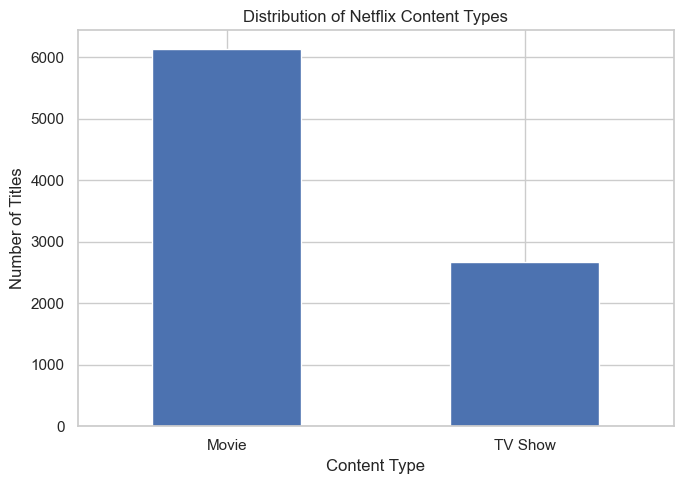

In [12]:
# Does the dataset contain more movies or TV shows?

content_counts = df["type"].value_counts()

print(content_counts)

content_counts.plot(
    kind="bar",
    figsize=(7, 5),
    title="Distribution of Netflix Content Types"
)

plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### Analyze Content by Country

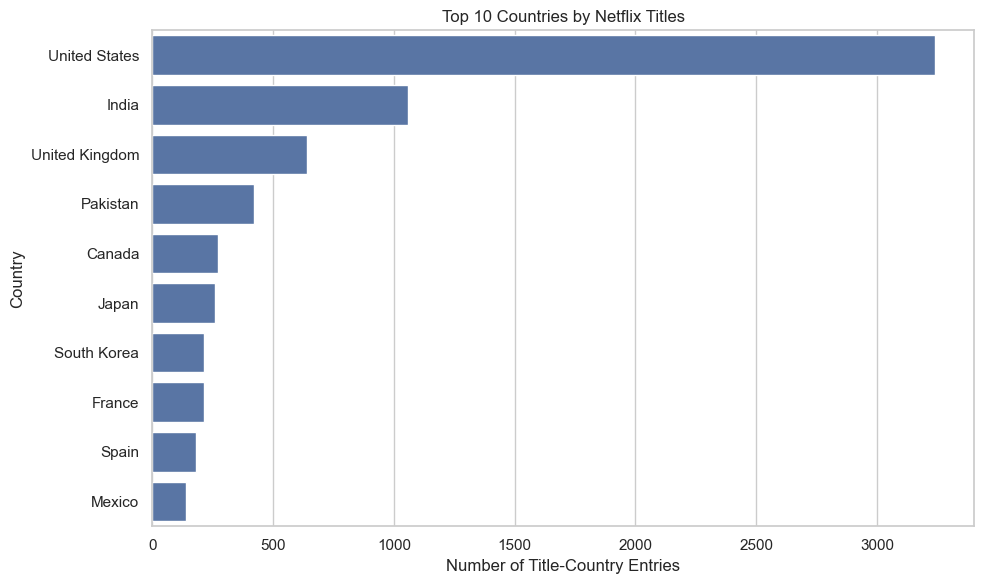

In [13]:
country_counts = (
    df["country"]
    .dropna()
    .str.split(", ")
    .explode()
)

country_counts = country_counts[
    country_counts != "Not Given"
]

top_countries = country_counts.value_counts().head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Netflix Titles")
plt.xlabel("Number of Title-Country Entries")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

#### Analyze the Most Common Genres

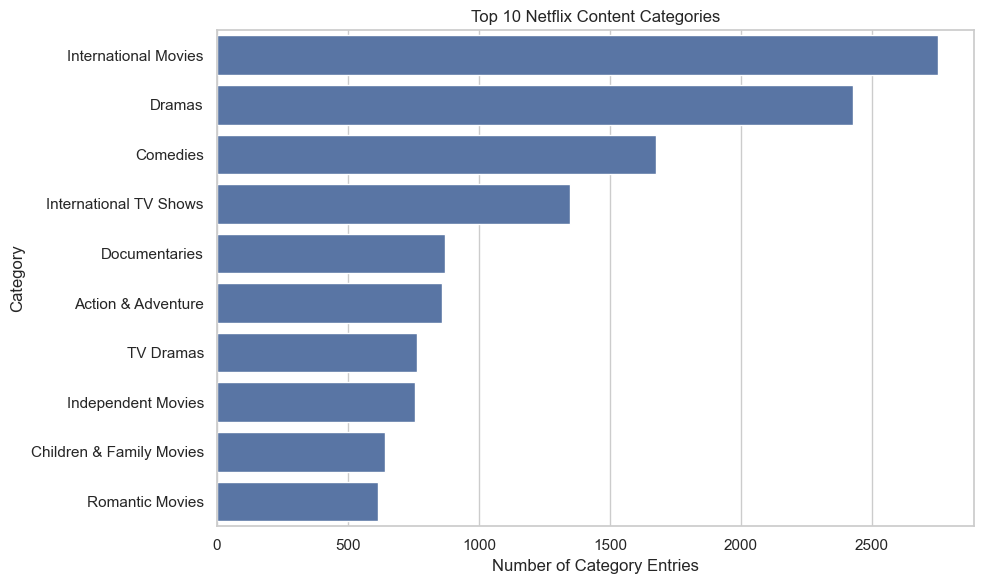

In [14]:
genre_counts = (
    df["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
)

plt.figure(figsize=(10, 6))

top_genres = genre_counts.value_counts().head(10)

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title("Top 10 Netflix Content Categories")
plt.xlabel("Number of Category Entries")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

#### Analyze Content by Release Year

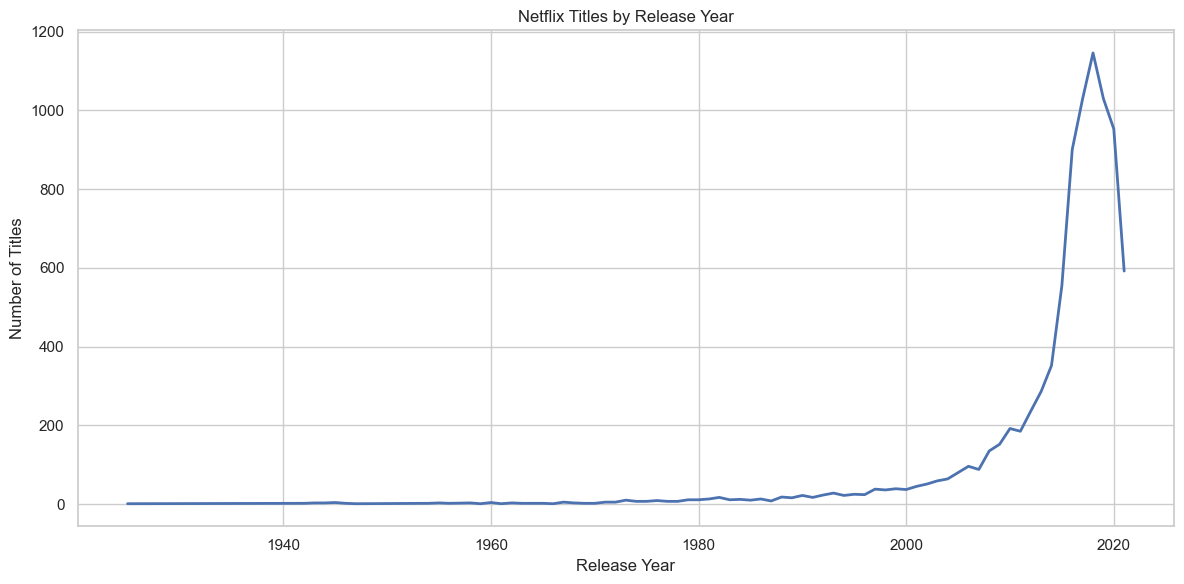

In [15]:
year_counts = df["release_year"].value_counts().sort_index()

plt.figure(figsize=(12, 6))

plt.plot(
    year_counts.index,
    year_counts.values,
    linewidth=2
)

plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

#### Analyze Netflix Content Added Over Time

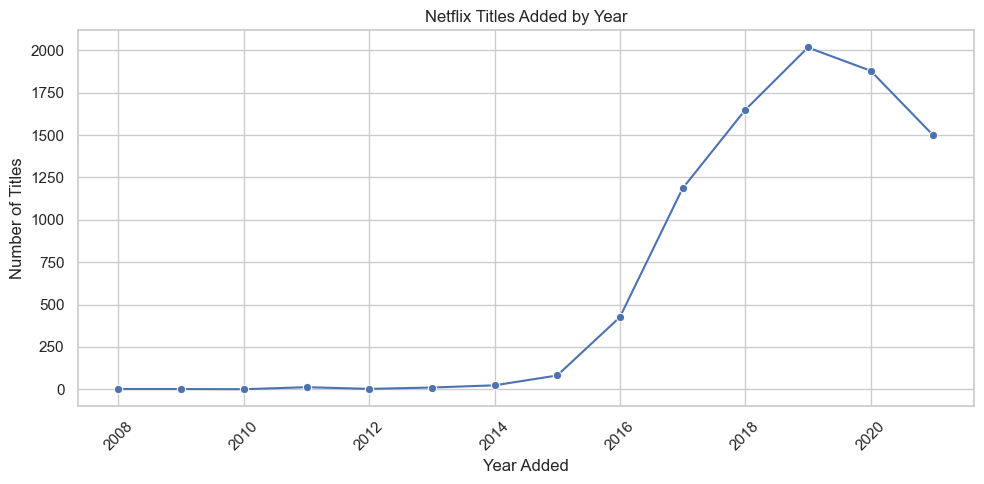

In [16]:
df["date_added"] = pd.to_datetime(
    df["date_added"],
    errors="coerce"
)

df["year_added"] = df["date_added"].dt.year



plt.figure(figsize=(10, 5))

added_counts = df["year_added"].value_counts().sort_index()

sns.lineplot(
    x=added_counts.index,
    y=added_counts.values,
    marker="o"
)

plt.title("Netflix Titles Added by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Task 2 : Project Conclusion

Exploratory Data Analysis was performed on the Netflix dataset using Python, Pandas, Matplotlib, and Seaborn. The dataset contains 8,790 records and 10 columns.

The analysis revealed that movies account for approximately 69.7% of the dataset, while TV shows account for approximately 30.3%. The United States was the most frequently represented country, followed by India and the United Kingdom. International Movies and Dramas were the most frequently represented content categories.

The release-year analysis showed substantial representation of titles released during the late 2010s, with 2018 having the highest count among the selected recent years examined. Additional analysis of the date-added column provides insight into the distribution of titles added to Netflix over time.

The visualizations made it easier to identify content patterns and communicate findings. These insights provide a foundation for the recommendation system and trend prediction projects.


# Task 3 : Recommendation System Analysis

In [17]:
from sklearn.feature_extraction.text import TfidfVectorizer # converts text information into numerical features.
from sklearn.metrics.pairwise import cosine_similarity  # measures how similar two titles are based on those features.

#### Select Relevant Features

In [18]:
features = ["type", "listed_in", "director", "country"]

df[features] = df[features].fillna("")

df["combined_features"] = (
    df["type"] + " " +
    df["listed_in"] + " " +
    df["director"] + " " +
    df["country"]
)

print(df[["title", "combined_features"]].head())

                              title  \
0              Dick Johnson Is Dead   
1                         Ganglands   
2                     Midnight Mass   
3  Confessions of an Invisible Girl   
4                           Sankofa   

                                   combined_features  
0  Movie Documentaries Kirsten Johnson United States  
1  TV Show Crime TV Shows, International TV Shows...  
2  TV Show TV Dramas, TV Horror, TV Mysteries Mik...  
3  Movie Children & Family Movies, Comedies Bruno...  
4  Movie Dramas, Independent Movies, Internationa...  


#### Convert Text into Numerical Features

In [19]:
tfidf = TfidfVectorizer(stop_words="english")

tfidf_matrix = tfidf.fit_transform(df["combined_features"])

print("Feature Matrix Shape:", tfidf_matrix.shape)

Feature Matrix Shape: (8790, 6559)


#### Calculate Similarity Between Titles

In [20]:
similarity_matrix = cosine_similarity(tfidf_matrix)

print("Similarity Matrix Shape:", similarity_matrix.shape)

Similarity Matrix Shape: (8790, 8790)


#### Build the Recommendation Function

In [21]:
def recommend_titles(title, top_n=5):
    matches = df[
        df["title"].str.casefold() == title.casefold()
    ]

    if matches.empty:
        print(f"Title '{title}' was not found.")
        return

    title_index = matches.index[0]

    scores = list(enumerate(similarity_matrix[title_index]))

    scores = sorted(
        scores,
        key=lambda item: item[1],
        reverse=True
    )

    recommendations = [
        (index, score)
        for index, score in scores
        if index != title_index
    ][:top_n]

    result = df.loc[
        [index for index, score in recommendations],
        ["title", "type", "release_year", "listed_in"]
    ].copy()

    result["similarity_score"] = [
        round(score, 3) for index, score in recommendations
    ]

    return result.reset_index(drop=True)

#### Test the Recommendation System

In [22]:
recommendations = recommend_titles("Ganglands")

if recommendations is not None:
    print("\nRecommended Netflix Titles:")
    print(recommendations.to_string(index=False))


Recommended Netflix Titles:
          title    type  release_year                                                     listed_in  similarity_score
     Sentinelle   Movie          2021              Action & Adventure, Dramas, International Movies             0.759
          Lupin TV Show          2021 Crime TV Shows, International TV Shows, TV Action & Adventure             0.730
     Crime Time TV Show          2017 Crime TV Shows, International TV Shows, TV Action & Adventure             0.730
Earth and Blood   Movie          2020                       Dramas, International Movies, Thrillers             0.688
          Taken TV Show          2018           Crime TV Shows, TV Action & Adventure, TV Thrillers             0.677


#### Evaluate the Recommendation System

In [23]:
recommendations = recommend_titles("Ganglands")

if recommendations is not None and not recommendations.empty:
    average_similarity = recommendations["similarity_score"].mean()

    print("Average Similarity Score:", round(average_similarity, 3))

Average Similarity Score: 0.717


## Task 3 : Project Conclusion

A content-based recommendation system was developed using Python, Pandas, and Scikit-learn. The Netflix dataset was processed by combining selected metadata features, including content type, genre, director, and country.

TF-IDF vectorization was used to transform textual metadata into numerical features, while cosine similarity was applied to measure similarity between titles. A recommendation function was implemented to identify and display the five most similar titles for a selected Netflix title.

The system demonstrates how machine learning techniques can be applied to content metadata to generate recommendations. Its effectiveness depends on the quality and availability of the selected features. Although the model provides a useful foundation, further evaluation using user feedback or labeled data would be necessary to assess recommendation quality more comprehensively.


# Task 4 : Trend Prediction Analysis

#### Prepare the Release_year data

In [24]:
df["release_year"] = pd.to_numeric(
    df["release_year"],
    errors="coerce"
)

yearly_counts = (
    df.dropna(subset=["release_year"])
      .groupby("release_year")
      .size()
      .reset_index(name="title_count")
)

yearly_counts["release_year"] = (
    yearly_counts["release_year"].astype(int)
)

print(yearly_counts.head())

   release_year  title_count
0          1925            1
1          1942            2
2          1943            3
3          1944            3
4          1945            4


#### Visualise Historical Trends

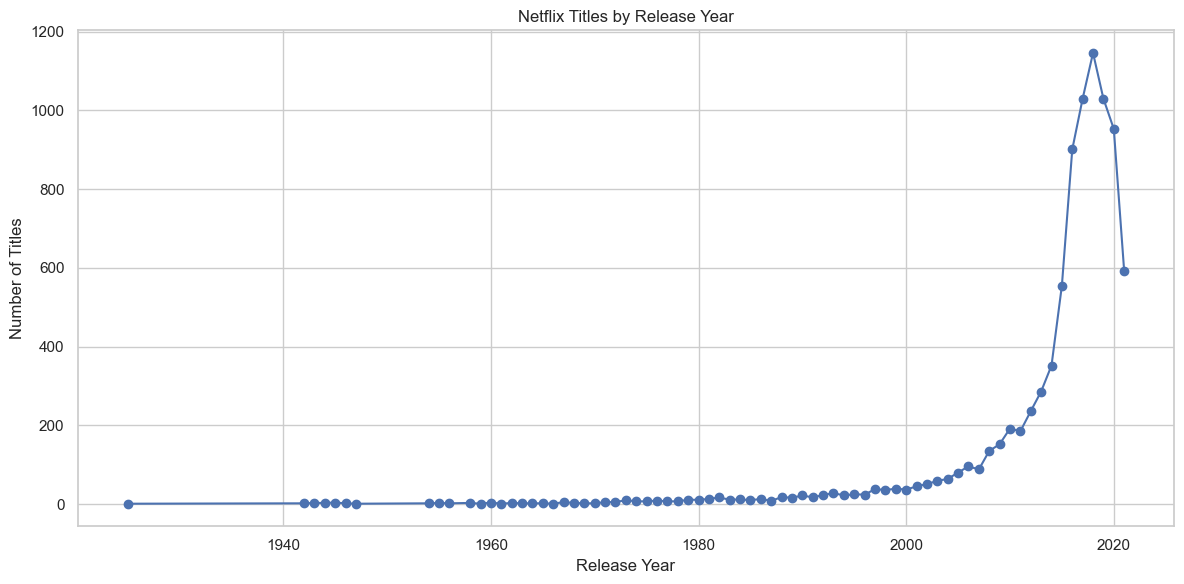

In [25]:
# a line chart showing how title counts vary by release year.
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_counts["release_year"],
    yearly_counts["title_count"],
    marker="o"
)

plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)
plt.tight_layout()
plt.show()

#### Prepare Data for machine learning

In [26]:
X = yearly_counts[["release_year"]]
y = yearly_counts["title_count"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (74, 1)
Target Shape: (74,)


#### Split the data into train and test sets

In [27]:
split_index = int(len(yearly_counts) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 59
Testing Records: 15


#### Train the forecasting model

In [28]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()

model.fit(X_train, y_train)

print("Model training completed.")

Model training completed.


#### Making Predictions

In [29]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "release_year": X_test["release_year"],
    "actual_count": y_test,
    "predicted_count": y_pred.round(0).astype(int)
})

print(results)

    release_year  actual_count  predicted_count
59          2007            88               41
60          2008           135               42
61          2009           152               43
62          2010           192               44
63          2011           185               45
64          2012           236               45
65          2013           286               46
66          2014           352               47
67          2015           555               48
68          2016           901               49
69          2017          1030               49
70          2018          1146               50
71          2019          1030               51
72          2020           953               52
73          2021           592               53


#### Evaluating the model

In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5

print("Mean Absolute Error:", round(mae, 2))
print("Root Mean Squared Error:", round(rmse, 2))

Mean Absolute Error: 475.14
Root Mean Squared Error: 603.2


#### Visualize Actual Vs Predicted Count

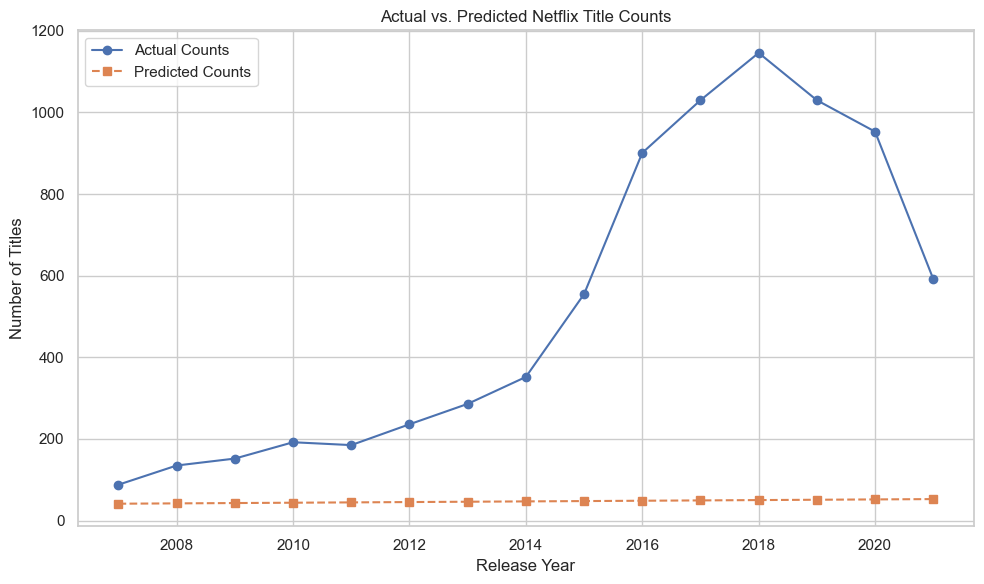

In [31]:
plt.figure(figsize=(10, 6))

plt.plot(
    X_test["release_year"],
    y_test,
    marker="o",
    label="Actual Counts"
)

plt.plot(
    X_test["release_year"],
    y_pred,
    marker="s",
    linestyle="--",
    label="Predicted Counts"
)

plt.title("Actual vs. Predicted Netflix Title Counts")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Baseline prediction: use the average training value
baseline_pred = [y_train.mean()] * len(y_test)

# Evaluate the baseline model
baseline_mae = mean_absolute_error(y_test, baseline_pred)

baseline_rmse = mean_squared_error(
    y_test, baseline_pred
) ** 0.5

# Compare both models
comparison = pd.DataFrame({
    "Model": ["Baseline Model", "Linear Regression"],
    "MAE": [baseline_mae, mae],
    "RMSE": [baseline_rmse, rmse]
})

print(comparison.round(2))

               Model     MAE    RMSE
0     Baseline Model  505.98  629.55
1  Linear Regression  475.14  603.20


## Task 4 : Project Conclusion

### Model Evaluation and Conclusion

A Linear Regression model was developed to analyse Netflix content release trends and predict the number of titles released.

The model was evaluated using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

The Linear Regression model achieved:
- MAE: 475.14
- RMSE: 603.20

A baseline model was also developed for comparison. It achieved an MAE of 505.98 and an RMSE of 629.55.

The Linear Regression model performed better than the baseline because it produced lower error values. However, the prediction errors indicate that the model still has limitations in accurately predicting future content trends.

Overall, this task demonstrated how historical Netflix release data can be used to analyse trends and develop a basic forecasting model.